# 04. 교육환경(학교·학원)과 가격의 관계

**질문:** 교육환경(학교·학원)은 가격과 어떤 관계가 있는가?

**방법과 지표**
- 기간: 일괄 거래 제외 기본 표본 중 **2024-01~2026-09** 거래. 교육 자료(학교 2026-10-01, 학원 2026-10 기준)가 현재 시점이므로 가장 가까운 기간만 쓴다.
- **주결과(동 단위 회귀):** 먼저 동별 구성 보정 가격 수준(log(㎡당 가격) ~ 동 FE + 연월 FE + 면적·연식·층 구간에서 얻은 동 FE)을 구한다. 이어서 거래 30건 이상 동에서 동 보정 가격 수준 ~ log(1+입시·보습 학원 수) + 초·중·고 학교 수 + **구 고정효과**를 추정한다.
  - 관측 단위가 동이므로 표준오차는 **동 단위 강건(HC1형)** 표준오차다.
  - 주변수에는 **wild bootstrap(Rademacher, 999회, 매 반복 구 FE로 다시 잔차화)** p값을 함께 본다.
  - 추정 대상은 "같은 구 안에서 동 하나하나를 같은 무게로 본 평균 연관"이다.
- 학원 계수 b는 **(1+학원 수)에 대한 탄력성**이다. (1+학원 수)가 1% 많은 동은 가격 수준이 약 b% 높다(예: b=0.03이면 약 0.03%). "학원 수가 두 배인 동과의 비교"는 기준 학원 수 A에 따라 달라지므로 100×[exp(b·log((1+2A)/(1+A)))−1]로 분석 동의 학원 수 사분위수(25%·중앙값·75%)에서 따로 계산한다(1-3절).
- **민감도**
  - 학원가 기준을 미리 정한 분위수(분석 동의 입시·보습 학원 수 상위 10%·20%·30%)로 바꾼 더미
  - 학원 유형 세분화(입시·보습 중 학원만, 국제화, 예능)
  - 교통 통제(log 역거리, 버스정류소 수)와 단지 규모(log 세대수 중앙값) 추가, 통근시간 추가(통근시간이 있는 동만)
  - **거래 단위 모형(이전 주 사양):** log(㎡당 가격) ~ 구×연월 FE + 면적·연식·층 구간 + 동 단위 교육 변수, 동 클러스터 SE. 이 모형은 거래가 많은 동에 더 큰 무게를 주고(거래 가중), 같은 구·같은 달 거래끼리 비교한다. 그래서 추정 대상이 동 단위 모형과 다르다.
- **연관규칙(서술용 보조):** 동 특성 {학원가, 노후 대단지, 역세권, 고가}가 함께 나타나는 패턴을 FP-Growth로 표로만 제시한다.
- **wild bootstrap 수정 확인:** 합성 자료로, 부호를 바꾼 가상 종속변수를 고정효과로 다시 잔차화하는 수정판과 수정 전 방식의 기각률을 비교한다(1-1절).

**사용한 교재 장:** 5장 다중회귀, 9장 연관규칙(FP-Growth, 보조).
**교재에서 바꾼 점과 이유:** 교재 5장 회귀는 거래를 독립 관측으로 다루지만, 교육 변수는 동마다 하나의 값이라 실효 표본은 동 수다. 그래서 동 단위로 모아 회귀하고, 동 단위 강건 표준오차와 wild bootstrap을 쓴다. 학원가 기준은 결과를 보고 고르지 않도록 분위수를 미리 정하고 기준별 민감도를 함께 보인다. 연관규칙은 이산화 기준에 결과가 좌우되고 인과가 아니므로 서술용 표로만 쓴다. 조율안에 보조로 적힌 얕은 트리(3장)·kNN 그림(4장)은 회귀·연관규칙으로 질문에 답할 수 있어 쓰지 않았다.

**주의:** 학원 수는 학군(학업성취·진학) 지표가 아니다. 비싼 동에 학원이 모이는 역인과 가능성이 있다. 학원·학교 자료는 현재 시점이다.

In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import reanalysis_utils as ru

SEED = ru.SEED
DATA = ROOT / "data"
plt = ru.set_korean_font()

In [2]:
from mlxtend.frequent_patterns import fpgrowth, association_rules

OUT = ru.out_dir(ROOT, "04")
feat = pd.read_parquet(ROOT / "outputs" / "재검증" / "00_정제" / "dong_features.parquet")
tx = ru.load_tx(ROOT)
PER = ru.ym_range("2024-01", "2026-09")
d = tx[tx["in_base_nobulk"] & tx["contract_ym"].isin(PER)].reset_index(drop=True)
d["gu_month"] = d["gu"] + "|" + d["contract_ym"]
n0 = len(d)
d = d.merge(feat, on=["dong_id"], how="left", suffixes=("", "_f"), validate="many_to_one")
assert len(d) == n0
pd.Series({"tx_rows": len(d), "dongs": d["dong_id"].nunique(), "feature_key_missing": int(d["n_school_total"].isna().sum())}).to_frame("n")

,n
tx_rows,181874
dongs,330
feature_key_missing,0


조인 키는 `dong_id`이며, 조인 전후 행 수가 같고 특징 결측이 없는지 확인했다(위 표).

## 1-1. wild bootstrap 수정 확인(합성 자료)
연월 고정효과가 동 클러스터를 가로지르는 구조(이 노트북의 거래 단위 모형, 06의 DID와 같은 구조)를 만들고, 참값이 0인 계수의 5% 기각률을 비교한다. 수정판은 부호를 바꾼 가상 종속변수를 매 반복 같은 고정효과로 다시 잔차화하고, 수정 전 방식은 그 단계를 건너뛴다. 기각률이 5%에 가까울수록 크기가 맞는 검정이다.

In [3]:
def synth_once(seed, G=30, T=12, per=8):
    rng = np.random.default_rng(seed)
    cl = np.repeat(np.arange(G), T * per)
    mon = np.tile(np.repeat(np.arange(T), per), G)
    x = rng.normal(size=G)[cl] + 0.5 * rng.normal(size=T)[mon]
    y = 3 * rng.normal(size=T)[mon] + 0.7 * rng.normal(size=G)[cl] + rng.normal(size=len(cl))
    r = ru.fe_ols(y, pd.DataFrame({"x": x}), [mon], clusters=cl)
    p_new, _ = ru.wild_cluster_boot_p(r, "x", cl, B=199, seed=seed, refe=True)
    p_old, _ = ru.wild_cluster_boot_p(r, "x", cl, B=199, seed=seed, refe=False)
    return p_new, p_old


sim = pd.DataFrame([synth_once(1000 + i) for i in range(300)], columns=["p_refe", "p_no_refe"])
pd.Series({"sims": len(sim), "reject5_refe(수정판)": (sim["p_refe"] < 0.05).mean(),
           "reject5_no_refe(수정 전)": (sim["p_no_refe"] < 0.05).mean(),
           "mean_abs_p_diff": (sim["p_refe"] - sim["p_no_refe"]).abs().mean()}).round(3)

sims                     300.000
reject5_refe(수정판)          0.030
reject5_no_refe(수정 전)      0.043
mean_abs_p_diff            0.007
dtype: float64

위 표는 귀무가설이 참인 합성 자료 300개에서의 5% 기각률이다. 수정 전 방식은 부호를 바꾼 잔차에 고정효과 성분이 남아 가상 표본의 잔차 분산이 커지고, 그만큼 가상 t값이 작아져 p값이 작게 나오는 쪽으로 치우친다. 이 합성 설계에서는 차이가 크지 않았지만(기각률과 평균 p 차이는 위 표), 실제 거래 단위 모형에서는 p값이 두 배 가까이 달라졌다(1-2절 저장 CSV의 `wild_boot_p_no_refe`). 아래 실제 자료 결과는 모두 수정판으로 계산했다.

## 1-2. 동 단위 주결과

In [4]:
MIN_TX = 30
lev, lev_res = ru.dong_level(d[["dong_id", "contract_ym", "log_ppa", "area_bin", "age_bin", "floor_bin"]].reset_index(drop=True))
dl = feat.merge(lev, on="dong_id", how="inner", validate="one_to_one")
dl["enough_tx"] = dl["n_tx"] >= MIN_TX
gm = dl.groupby("gu")["adj_log_level"].transform(lambda s: np.average(s, weights=dl.loc[s.index, "n_tx"]))
dl["level_within_gu"] = dl["adj_log_level"] - gm
sc = dl[dl["enough_tx"]].reset_index(drop=True)
Q = {q: sc["acad_exam"].quantile(1 - q) for q in (0.10, 0.20, 0.30)}
for df_ in (sc, d, dl):
    for q, thr in Q.items():
        df_[f"acad_top{int(q * 100)}"] = (df_["acad_exam"] >= thr).astype(float)
    df_["log_acad_exam"] = np.log1p(df_["acad_exam"])
    df_["log_acad_exam_hagwon"] = np.log1p(df_["acad_exam_hagwon"])
    df_["log_acad_lang"] = np.log1p(df_["acad_lang"])
    df_["log_acad_arts"] = np.log1p(df_["acad_arts"])
    df_["log_subway"] = np.log(df_["subway_dist_m"])
    df_["log_hh"] = np.log(df_["apt_households_median"])
display(pd.Series({"dongs_with_level": len(dl), "analysis_dongs(n_tx>=30)": len(sc), "tx_for_level": int(lev_res["n"])}).to_frame("n"))
pd.DataFrame({"quantile": ["상위10%", "상위20%", "상위30%"], "acad_exam_threshold": list(Q.values()),
              "dongs_in_group": [int((sc["acad_exam"] >= t).sum()) for t in Q.values()]})

,n
dongs_with_level,330
analysis_dongs(n_tx>=30),259
tx_for_level,181874


,quantile,acad_exam_threshold,dongs_in_group
0,상위10%,120.4,26
1,상위20%,76.8,52
2,상위30%,55.0,80


동 보정 가격 수준은 거래 181,874건으로 추정했고, 회귀에는 거래 30건 이상 동만 쓴다(05와 같은 기준). 학원가 기준값은 이 분석 동의 입시·보습 학원 수 분위수로 미리 정했다(위 표).

In [5]:
SCH = ["n_school_elem", "n_school_middle", "n_school_high"]


def run_dong(cols, sub=None, label=""):
    dm = sc if sub is None else sc[sub(sc)].reset_index(drop=True)
    res = ru.fe_ols(dm["adj_log_level"].to_numpy(), dm[cols].reset_index(drop=True), [dm["gu"].to_numpy()],
                    clusters=dm["dong_id"].to_numpy(), dof_absorbed=True)
    ct = ru.coef_table(res)
    ct = ct[ct["term"].isin(cols)].copy()
    ct["model"], ct["spec"], ct["n"], ct["n_dong"] = "동 단위(주)", label, res["n"], res["n"]
    return ct, res, dm


def run_tx(cols, sub=None, label=""):
    dm = d if sub is None else d[sub(d)].reset_index(drop=True)
    X = pd.concat([dm[cols].reset_index(drop=True), ru.dummies(dm, ru.CHAR_REFS).reset_index(drop=True)], axis=1)
    res = ru.fe_ols(dm["log_ppa"].to_numpy(), X, [dm["gu_month"].to_numpy()], clusters=dm["dong_id"].to_numpy())
    ct = ru.coef_table(res)
    ct = ct[ct["term"].isin(cols)].copy()
    ct["model"], ct["spec"], ct["n"], ct["n_dong"] = "거래 단위(민감도)", label, res["n"], res["n_clusters"]
    return ct, res, dm


TRANSIT = lambda x: x["log_subway"].notna() & x["log_hh"].notna()
COMMUTE = lambda x: TRANSIT(x) & x["commute_min"].notna()
SPECS = [("S1 주 사양", ["log_acad_exam"] + SCH, None, "log_acad_exam"),
         ("학원가 상위10%", ["acad_top10"] + SCH, None, "acad_top10"),
         ("학원가 상위20%", ["acad_top20"] + SCH, None, "acad_top20"),
         ("학원가 상위30%", ["acad_top30"] + SCH, None, "acad_top30"),
         ("학원 유형 세분화", ["log_acad_exam_hagwon", "log_acad_lang", "log_acad_arts"] + SCH, None, None),
         ("S1 같은 표본(교통 자료 있는 동)", ["log_acad_exam"] + SCH, TRANSIT, "log_acad_exam"),
         ("교통·단지규모 통제", ["log_acad_exam"] + SCH + ["log_subway", "bus_n_500m", "log_hh"], TRANSIT, "log_acad_exam"),
         ("통근시간 추가", ["log_acad_exam"] + SCH + ["log_subway", "bus_n_500m", "log_hh", "commute_min"], COMMUTE, "log_acad_exam")]
specs, boot_rows = [], []
for label, cols, sub, bterm in SPECS:
    ct, r, dm = run_dong(cols, sub, label)
    specs.append(ct)
    if bterm:
        pb, _ = ru.wild_cluster_boot_p(r, bterm, dm["dong_id"].to_numpy(), B=999)
        boot_rows.append({"model": "동 단위(주)", "term": bterm, "spec": label, "wild_boot_p": pb})
for label, cols, sub, bterm in [SPECS[0], SPECS[2], SPECS[6]]:
    ct, r, dm = run_tx(cols, sub, label)
    specs.append(ct)
    pb, _ = ru.wild_cluster_boot_p(r, bterm, dm["dong_id"].to_numpy(), B=999)
    pb_old, _ = ru.wild_cluster_boot_p(r, bterm, dm["dong_id"].to_numpy(), B=999, refe=False)
    boot_rows.append({"model": "거래 단위(민감도)", "term": bterm, "spec": label, "wild_boot_p": pb, "wild_boot_p_no_refe": pb_old})
allc = pd.concat(specs, ignore_index=True).merge(pd.DataFrame(boot_rows), on=["model", "term", "spec"], how="left")
allc["pct"] = np.where(allc["term"].str.startswith("acad_top") | allc["term"].str.startswith("n_school"),
                       (np.exp(allc["coef"]) - 1) * 100, allc["coef"])
key_terms = allc[allc["term"].str.contains("acad")]
key_terms[["model", "spec", "term", "coef", "se", "p_value", "wild_boot_p", "ci_low", "ci_high", "n", "n_dong"]].round(4)

,model,spec,term,coef,se,p_value,wild_boot_p,ci_low,ci_high,n,n_dong
0,동 단위(주),S1 주 사양,log_acad_exam,0.0317,0.0159,0.0478,0.050,0.0003,0.0630,259,259
4,동 단위(주),학원가 상위10%,acad_top10,0.1185,0.0571,0.0390,0.045,0.0060,0.2310,259,259
8,동 단위(주),학원가 상위20%,acad_top20,0.0487,0.0422,0.2503,0.259,-0.0345,0.1319,259,259
12,동 단위(주),학원가 상위30%,acad_top30,0.0522,0.0400,0.1938,0.200,-0.0267,0.1310,259,259
16,동 단위(주),학원 유형 세분화,log_acad_exam_hagwon,-0.0069,0.0253,0.7844,NaN,-0.0568,0.0429,259,259
17,동 단위(주),학원 유형 세분화,log_acad_lang,0.0229,0.0274,0.4030,NaN,-0.0310,0.0769,259,259
18,동 단위(주),학원 유형 세분화,log_acad_arts,0.0331,0.0326,0.3101,NaN,-0.0310,0.0973,259,259
22,동 단위(주),S1 같은 표본(교통 자료 있는 동),log_acad_exam,0.0324,0.0160,0.0435,0.039,0.0010,0.0639,255,255
26,동 단위(주),교통·단지규모 통제,log_acad_exam,0.0374,0.0148,0.0123,0.013,0.0082,0.0665,255,255
33,동 단위(주),통근시간 추가,log_acad_exam,0.0351,0.0142,0.0141,0.012,0.0072,0.0631,255,255


- `model=동 단위(주)`: 동 보정 가격 수준을 동마다 같은 무게로 회귀했다. `se`는 동 단위 강건 표준오차, `p_value`는 자유도(동 수 − 계수 수 − 구 FE 수)를 쓴 t검정, `wild_boot_p`는 동 단위 wild bootstrap(매 반복 구 FE로 다시 잔차화) p값이다.
- `model=거래 단위(민감도)`: 거래 하나하나를 관측으로 쓰고 동 클러스터 표준오차를 썼다. 거래가 많은 동의 무게가 크다. 이 행의 `wild_boot_p_no_refe`(저장 CSV)는 수정 전 방식 p값으로, 비교용이다.
- 학원가 더미 계수는 (e^b−1)×100 %로 읽는다(`pct` 열).

In [6]:
allc[allc["term"].str.startswith("n_school")][["model", "spec", "term", "coef", "se", "p_value"]].round(4)

,model,spec,term,coef,se,p_value
1,동 단위(주),S1 주 사양,n_school_elem,-0.0142,0.0107,0.1877
2,동 단위(주),S1 주 사양,n_school_middle,-0.0022,0.0168,0.8980
3,동 단위(주),S1 주 사양,n_school_high,0.0283,0.0123,0.0227
5,동 단위(주),학원가 상위10%,n_school_elem,-0.0098,0.0103,0.3409
6,동 단위(주),학원가 상위10%,n_school_middle,0.0064,0.0175,0.7147
7,동 단위(주),학원가 상위10%,n_school_high,0.0221,0.0138,0.1102
9,동 단위(주),학원가 상위20%,n_school_elem,-0.0091,0.0104,0.3844
10,동 단위(주),학원가 상위20%,n_school_middle,0.0024,0.0170,0.8886
11,동 단위(주),학원가 상위20%,n_school_high,0.0284,0.0125,0.0245
13,동 단위(주),학원가 상위30%,n_school_elem,-0.0098,0.0108,0.3638


## 1-3. 학원 수 두 배 비교(기준값별)
탄력성 b는 log(1+A)에 대한 계수이므로, 학원 수 A가 두 배(2A)일 때의 차이는 100×[exp(b·log((1+2A)/(1+A)))−1] %이고 A에 따라 다르다. 분석 동(259개)의 입시·보습 학원 수 25% 분위·중앙값·75% 분위를 기준값으로 쓰고, 95% 신뢰구간 끝값의 b로 같은 계산을 한다.

In [7]:
a_main = allc[(allc["model"] == "동 단위(주)") & (allc["spec"] == "S1 주 사양") & (allc["term"] == "log_acad_exam")].iloc[0]
A_REF = {"p25": float(sc["acad_exam"].quantile(0.25)), "median": float(sc["acad_exam"].median()), "p75": float(sc["acad_exam"].quantile(0.75))}


def double_pct(b, A):
    return 100 * (np.exp(b * np.log((1 + 2 * A) / (1 + A))) - 1)


dbl = pd.DataFrame([{"ref": k, "A": v, "pct": double_pct(a_main["coef"], v), "pct_lo": double_pct(a_main["ci_low"], v),
                     "pct_hi": double_pct(a_main["ci_high"], v)} for k, v in A_REF.items()])
dbl.round(3)

,ref,A,pct,pct_lo,pct_hi
0,p25,4.0,1.879,0.019,3.774
1,median,22.0,2.149,0.021,4.321
2,p75,66.5,2.196,0.022,4.417


## 2. 동 단위 산점도

In [8]:
pd.Series({"dongs_scatter": len(sc), "spearman_acad_vs_level_within_gu": sc["log_acad_exam"].corr(sc["level_within_gu"], method="spearman"),
           "spearman_acad_vs_level": sc["log_acad_exam"].corr(sc["adj_log_level"], method="spearman")}).round(3)

dongs_scatter                       259.000
spearman_acad_vs_level_within_gu      0.054
spearman_acad_vs_level               -0.075
dtype: float64

`level_within_gu`는 동 보정 가격 수준에서 구 평균(거래 가중)을 뺀 값이다. 구 안에서의 순위 상관(spearman)과 서울 전체 순위 상관을 비교하면, 학원 수와 가격의 연관이 구 간 차이에서 얼마나 오는지 알 수 있다.

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(sc["log_acad_exam"], sc["adj_log_level"] * 100, s=12, alpha=0.6)
axes[0].set_xlabel("log(1+입시·보습 학원 수)")
axes[0].set_ylabel("동 보정 가격 수준(서울 평균 대비 log×100)")
axes[0].set_title("학원 수와 동 보정 가격 수준 (2024-01~2026-09)", fontsize=10)
axes[1].scatter(sc["log_acad_exam"], sc["level_within_gu"] * 100, s=12, alpha=0.6, color="C1")
axes[1].set_xlabel("log(1+입시·보습 학원 수)")
axes[1].set_ylabel("구 평균 대비 동 가격 수준(log×100)")
axes[1].set_title("같은 구 안에서 비교 (2024-01~2026-09)", fontsize=10)
fig.text(0.01, -0.02, f"거래 {MIN_TX}건 이상 동 {len(sc)}개. 자료: outputs/재검증/04/fig_acad_scatter.csv", fontsize=8)
fig.tight_layout()
ru.save_png(fig, OUT, "fig_acad_scatter.png")
plt.close(fig)

## 3. 연관규칙(서술용 보조)
항목 정의(미리 고정):
- `학원가`: 입시·보습 학원 수 상위 20% 동
- `노후대단지`: 거래 단지 연식 중앙값(2026−건축년도 중앙값) 30년 이상 **그리고** 단지 세대수 중앙값 500세대 이상
- `역세권`: 최근접 지하철역 거리(단지 중앙값) 500m 이하
- `고가`: 동 보정 가격 수준 상위 20%(2024-01~2026-09, 거래 30건 이상 동)

In [10]:
ar = sc.copy()
ar["학원가"] = ar["acad_exam"] >= Q[0.20]
ar["노후대단지"] = ((2026 - ar["median_build_year"]) >= 30) & (ar["apt_households_median"] >= 500)
ar["역세권"] = ar["subway_dist_m"] <= 500
ar["고가"] = ar["adj_log_level"] >= ar["adj_log_level"].quantile(0.80)
items = ar[["학원가", "노후대단지", "역세권", "고가"]].astype(bool)
fi = fpgrowth(items, min_support=0.03, use_colnames=True)
rules = association_rules(fi, metric="lift", min_threshold=0.0)
rules["antecedents"] = rules["antecedents"].apply(lambda s: " & ".join(sorted(s)))
rules["consequents"] = rules["consequents"].apply(lambda s: " & ".join(sorted(s)))
rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]].sort_values("lift", ascending=False)
rules["n_dongs"] = (rules["support"] * len(items)).round().astype(int)
display(items.mean().rename("item_share").round(3).to_frame().T)
rules[rules["consequents"] == "고가"].round(3)

,학원가,노후대단지,역세권,고가
item_share,0.201,0.058,0.664,0.201


,antecedents,consequents,support,confidence,lift,n_dongs
8,역세권 & 학원가,고가,0.039,0.370,1.845,10
1,역세권,고가,0.154,0.233,1.158,40
5,학원가,고가,0.046,0.231,1.149,12


`support`는 해당 항목 조합을 모두 가진 동의 비율, `confidence`는 앞 조건을 가진 동 중 뒤 항목도 가진 비율, `lift`는 confidence를 뒤 항목의 전체 비율로 나눈 값이다(1보다 크면 함께 나타나는 경향). 향상도는 함께 나타나는 정도일 뿐 원인이 아니며, 동 수(`n_dongs`)가 적은 규칙은 불안정하다.

## 4. 저장

In [11]:
ru.save_chart_csv(allc[["model", "spec", "term", "coef", "se", "p_value", "wild_boot_p", "wild_boot_p_no_refe", "ci_low", "ci_high", "pct", "n", "n_dong"]],
                  OUT, "fig_sensitivity_table.csv")
ru.save_chart_csv(sim.round(6), OUT, "table_wild_boot_synthetic_check.csv")
ru.save_chart_csv(dl[["dong", "gu", "dong_id", "lat", "lon", "acad_exam", "acad_total", "n_school_total", "adj_log_level",
                      "level_within_gu", "n_tx", "enough_tx"]], OUT, "fig_acad_scatter.csv")
ru.save_chart_csv(rules.round(4), OUT, "fig_assoc_rules.csv")

rows = []


def add(key, label, value, unit, n, note, src, claim="통계적 연관", ps="2024-01", pe="2026-09"):
    rows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                 "period": f"{ps}~{pe}", "period_start": ps, "period_end": pe, "split_type": "없음",
                 "claim_level": claim, "source_file": src, "note": note})


M = "동 단위(주)"
a1 = allc[(allc["model"] == M) & (allc["spec"] == "S1 주 사양") & (allc["term"] == "log_acad_exam")].iloc[0]
add("acad_elasticity_main", "(1+입시·보습 학원 수)에 대한 동 가격 수준 탄력성(동 단위, 구 FE)", a1["coef"], "탄력성(Δlog 가격/Δlog(1+학원 수))", a1["n"],
    f"동 단위 강건 SE {a1['se']:.4f}, 95% CI {a1['ci_low']:.3f}~{a1['ci_high']:.3f}, p={a1['p_value']:.3g}, wild bootstrap p={a1['wild_boot_p']:.3g}, 동 {int(a1['n_dong'])}개(거래 30건 이상)",
    "fig_sensitivity_table.csv")
for q in (10, 20, 30):
    r = allc[(allc["model"] == M) & (allc["spec"] == f"학원가 상위{q}%") & (allc["term"] == f"acad_top{q}")].iloc[0]
    add(f"acad_top{q}_pct", f"학원가(입시·보습 상위{q}% 동) 동 가격 수준 차이(동 단위)", r["pct"], "%", r["n"],
        f"p={r['p_value']:.3g}, wild bootstrap p={r['wild_boot_p']:.3g}, 동 {int(r['n_dong'])}개", "fig_sensitivity_table.csv")
for spec, kk in [("S1 같은 표본(교통 자료 있는 동)", "samesample"), ("교통·단지규모 통제", "transit"), ("통근시간 추가", "commute")]:
    r = allc[(allc["model"] == M) & (allc["spec"] == spec) & (allc["term"] == "log_acad_exam")].iloc[0]
    add(f"acad_elasticity_{kk}", f"{spec} 사양의 (1+학원 수) 탄력성(동 단위)", r["coef"], "탄력성(Δlog 가격/Δlog(1+학원 수))", r["n"],
        f"p={r['p_value']:.3g}, wild bootstrap p={r['wild_boot_p']:.3g}, 동 {int(r['n_dong'])}개", "fig_sensitivity_table.csv")
for spec, kk in [("S1 주 사양", "main"), ("학원가 상위20%", "top20"), ("교통·단지규모 통제", "transit")]:
    tm = "acad_top20" if kk == "top20" else "log_acad_exam"
    r = allc[(allc["model"] == "거래 단위(민감도)") & (allc["spec"] == spec) & (allc["term"] == tm)].iloc[0]
    add(f"acad_tx_level_{kk}", f"거래 단위 모형 {spec} 계수(민감도)", r["pct"] if kk == "top20" else r["coef"],
        "%" if kk == "top20" else "탄력성(Δlog 가격/Δlog(1+학원 수))", r["n"],
        f"거래 가중·구×연월 FE, 동 클러스터 {int(r['n_dong'])}개, p={r['p_value']:.3g}, wild p={r['wild_boot_p']:.3g}(수정 전 방식 {r['wild_boot_p_no_refe']:.3g})",
        "fig_sensitivity_table.csv")
for _, r in dbl.iterrows():
    add(f"acad_double_pct_at_{r['ref']}", f"학원 수가 기준값 A={r['A']:g}개({r['ref']})에서 2배일 때 동 가격 수준 차이(동 단위)", r["pct"], "%", len(sc),
        f"100×[exp(b·log((1+2A)/(1+A)))−1], b={a_main['coef']:.4f}, b의 95% CI로 {r['pct_lo']:.2f}~{r['pct_hi']:.2f}%", "fig_sensitivity_table.csv")
for t in SCH:
    r = allc[(allc["model"] == M) & (allc["spec"] == "S1 주 사양") & (allc["term"] == t)].iloc[0]
    add(f"{t}_pct", f"{t} 1개당 동 가격 수준 차이(동 단위)", r["pct"], "%", r["n"], f"p={r['p_value']:.3g}", "fig_sensitivity_table.csv")
add("wild_boot_synth_reject5_refe", "합성 자료 5% 기각률(wild bootstrap 수정판)", (sim["p_refe"] < 0.05).mean(), "비율", len(sim),
    f"귀무 참, 수정 전 방식 {(sim['p_no_refe'] < 0.05).mean():.3f}", "table_wild_boot_synthetic_check.csv", "단순 변화")
add("spearman_acad_level_within_gu", "학원 수와 구 안 동 가격 수준의 순위상관", sc["log_acad_exam"].corr(sc["level_within_gu"], method="spearman"),
    "상관계수", len(sc), f"거래 {MIN_TX}건 이상 동", "fig_acad_scatter.csv")
hr = rules[(rules["antecedents"] == "학원가") & (rules["consequents"] == "고가")]
if len(hr):
    add("rule_acad_to_high_lift", "연관규칙 학원가→고가 향상도", hr["lift"].iloc[0], "lift", len(items),
        f"support {hr['support'].iloc[0]:.3f}, confidence {hr['confidence'].iloc[0]:.3f}, 서술용", "fig_assoc_rules.csv")
summary = ru.save_summary(rows, OUT)
ru.save_meta({
    "question": "교육환경(학교·학원)은 가격과 어떤 관계가 있는가?",
    "method": "주결과: 동 보정 가격 수준(동 FE+연월 FE+면적·연식·층 구간) ~ 학원·학교 변수 + 구 FE, 동 단위 강건 SE, wild bootstrap(매 반복 구 FE 재잔차화). 민감도: 학원가 분위수(10/20/30%)·학원 유형·교통·통근 통제, 거래 단위 모형(구×연월 FE, 동 클러스터, 거래 가중). FP-Growth 연관규칙(서술용)",
    "textbook_chapters": ["5장 다중회귀", "9장 연관규칙(FP-Growth, 보조)"],
    "sample_period": "2024-01~2026-09", "sample_size": {"tx_for_dong_level": int(lev_res["n"]), "analysis_dongs": len(sc)},
    "data_files": ["outputs/재검증/00_정제/transactions.parquet", "outputs/재검증/00_정제/dong_features.parquet"],
    "limitations": ["학원·학교 자료는 현재 시점(2026-10)", "학원 수는 학군 지표가 아니다", "비싼 동에 학원이 모이는 역인과 가능성",
                    "실효 표본은 동 수", "학원 동 배정은 괄호 주소 기준이라 일부 누락", "연관규칙은 이산화 기준에 좌우되며 인과가 아니다",
                    "2026-08~09는 잠정 월"],
}, OUT)
summary[["key", "value", "note"]]

,key,value,note
0,acad_elasticity_main,0.031674,"동 단위 강건 SE 0.0159, 95% CI 0.000~0.063, p=0.047..."
1,acad_top10_pct,12.580065,"p=0.039, wild bootstrap p=0.045, 동 259개"
2,acad_top20_pct,4.986502,"p=0.25, wild bootstrap p=0.259, 동 259개"
3,acad_top30_pct,5.354167,"p=0.194, wild bootstrap p=0.2, 동 259개"
4,acad_elasticity_samesample,0.032408,"p=0.0435, wild bootstrap p=0.039, 동 255개"
5,acad_elasticity_transit,0.037362,"p=0.0123, wild bootstrap p=0.013, 동 255개"
6,acad_elasticity_commute,0.035140,"p=0.0141, wild bootstrap p=0.012, 동 255개"
7,acad_tx_level_main,0.038986,"거래 가중·구×연월 FE, 동 클러스터 330개, p=0.0127, wild p=0..."
8,acad_tx_level_top20,1.912136,"거래 가중·구×연월 FE, 동 클러스터 330개, p=0.571, wild p=0...."
9,acad_tx_level_transit,0.059661,"거래 가중·구×연월 FE, 동 클러스터 272개, p=2.83e-06, wild p..."


## 결론
주결과는 거래 30건 이상 259개 동의 동 단위 회귀(동 보정 가격 수준, 2024-01~2026-09 거래 181,874건으로 추정, 구 FE, 동 단위 강건 SE)이며, 모두 통계적 연관이다(`fig_sensitivity_table.csv`).
- **학원 수(연속 변수):** 같은 구 안에서 입시·보습 학원이 많은 동일수록 가격 수준이 높은 경향이 약하게 나타났다. (1+학원 수)에 대한 탄력성은 0.032(95% CI 0.000~0.063, p=0.048, wild bootstrap p=0.050)로 **5% 경계선에 있다.** (1+학원 수)가 1% 많으면 가격 수준이 약 0.03% 높다는 뜻이다. 학원 수가 두 배인 동과 비교하면 기준값에 따라 학원 4개(25% 분위) 동은 +1.9%, 22개(중앙값) 동은 +2.1%, 66.5개(75% 분위) 동은 +2.2%다(b의 95% CI로 0.02~4.4%, 1-3절). 교통·단지 규모를 통제하면 탄력성이 0.037(wild p=0.013, 255개 동)이었고, 같은 255개 동에서 통제 없이 추정하면 0.032(wild p=0.039)였다.
- **거래 단위 모형(민감도):** 거래 가중·구×연월 FE 모형에서는 탄력성 0.039(동 클러스터 p=0.013, 수정한 wild p=0.036; 수정 전 방식 0.018)였다. 거래가 많은 동에 무게가 실리는 모형이라 동 단위 결과보다 조금 크다.
- **학원가 더미(기준 민감도):** 분석 동 기준 상위 10%(입시·보습 120개 이상, 26개 동)는 +12.6%(wild p=0.045)였지만, 상위 20%·30%는 +5.0%(0.26), +5.4%(0.20)로 유의하지 않았다. 기준에 따라 결론이 바뀐다.
- **학원 유형:** 입시·보습 학원(교습소 제외), 국제화, 예능 학원을 함께 넣으면 어느 유형도 유의하지 않았다.
- **학교 수:** 고등학교 1개당 +2.9%(p=0.023)였지만 교통·단지 규모를 통제하면 +1.4%(p=0.22)로 줄었다. 초·중학교 수는 음(−)이거나 유의하지 않았다.
- **동 단위 순위상관:** 학원 수와 동 보정 가격의 순위상관은 서울 전체 −0.08, 같은 구 안 0.05로 약했다(`fig_acad_scatter.csv`).
- **연관규칙(서술용):** {역세권, 학원가} → 고가 향상도 1.85(동 10개), 학원가 → 고가 1.15(동 12개)였다. 동 수가 적어 불안정하다(`fig_assoc_rules.csv`).
- **wild bootstrap 수정:** 매 반복 고정효과로 다시 잔차화하도록 고쳤다. 합성 자료 5% 기각률은 수정판 3.0%, 수정 전 4.3%였다(`table_wild_boot_synthetic_check.csv`).

## 한계
- 학원·학교 자료는 2026-10 현재 시점이다. 2024~2026 거래와 가장 가깝게 맞췄지만 시점 차이는 남는다.
- 학원 수는 학군(학업성취·진학 실적) 지표가 아니다. 비싼 동에 학원이 모이는 역인과, 상권 규모 같은 누락 변수가 계수에 섞여 있을 수 있다.
- 동 단위 회귀는 거래 30건 이상 동(259개)만 쓴다. 거래가 적은 동은 빠진다.
- 동 단위 모형은 동마다 같은 무게, 거래 단위 모형은 거래 수에 비례한 무게를 주므로 두 계수는 추정 대상이 다르다.
- 학원은 도로명상세주소 괄호의 법정동으로 배정해 약 4%가 빠졌고, 구별 미배정률이 다르다(종로 38%, 중구 27%).
- 연관규칙은 이산화 기준에 결과가 좌우되며 원인을 뜻하지 않는다.
- 2026-08~09는 잠정 월이다.

## 시각화 (발표용): 학원 수와 동 가격 수준

`fig_acad_scatter.csv`로 그린다. 점 하나가 동 하나이고, 거래 30건 이상인 동만 그렸다.
- 가로축은 입시·보습 학원 수(1+학원 수, 로그 눈금)이다.
- 세로축은 같은 구 평균과 비교한 동 가격 수준이다. 면적·연식·층을 맞춘 값이고, 2024-01~2026-09 거래로 구했다.
- 선은 이 그림의 점으로만 그린 단순 추세선이다. 본문 회귀(구 고정효과, 학교 수 통제)의 탄력성은 주석에 적었다.

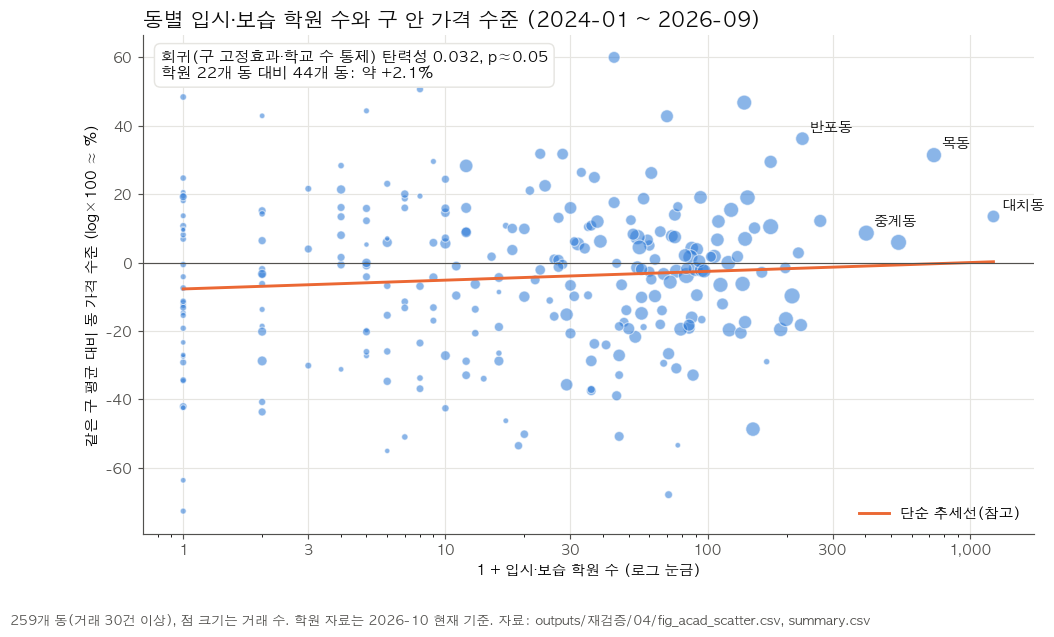

In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager

_fonts = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["AppleGothic", "NanumGothic", "Malgun Gothic"]:
    if _name in _fonts:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # 범주 색 고정 순서
INK, INK2, GRID, BAND = "#0b0b0b", "#52514e", "#e6e5e1", "#f0efec"


def style(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(INK2)
    ax.tick_params(colors=INK2)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name):
    """폭 1200px 이하 PNG로 저장하고 노트북에 표시한다(이 노트북은 Agg 백엔드라 plt.show()로는 보이지 않음)."""
    from IPython.display import Image, display
    w = fig.get_size_inches()[0]
    fig.savefig(OUT / name, dpi=min(110, 1150 / w), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(OUT / name)))

OUT = ROOT / "outputs" / "재검증" / "04"
s = pd.read_csv(OUT / "fig_acad_scatter.csv")
s = s[s["enough_tx"]].copy()
sm = pd.read_csv(OUT / "summary.csv").set_index("key")["value"]
s["x"] = 1 + s["acad_exam"]
s["y"] = s["level_within_gu"] * 100

fig, ax = plt.subplots(figsize=(11, 6.2))
ax.scatter(s["x"], s["y"], s=np.clip(np.sqrt(s["n_tx"]) * 2.2, 12, 120), color=SERIES[0], alpha=0.55,
           edgecolor="white", lw=0.8)
b = np.polyfit(np.log(s["x"]), s["y"], 1)
xs = np.exp(np.linspace(np.log(s["x"].min()), np.log(s["x"].max()), 50))
ax.plot(xs, np.polyval(b, np.log(xs)), color=SERIES[1], lw=2, label="단순 추세선(참고)")
for name in ["강남구 대치동", "양천구 목동", "노원구 중계동", "서초구 반포동"]:
    r = s[s["dong_id"] == name]
    if len(r):
        ax.annotate(name.split()[1], (r["x"].iat[0], r["y"].iat[0]), xytext=(5, 5),
                    textcoords="offset points", fontsize=10, color=INK)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 300, 1000], ["1", "3", "10", "30", "100", "300", "1,000"])
ax.set_xlabel("1 + 입시·보습 학원 수 (로그 눈금)")
ax.set_ylabel("같은 구 평균 대비 동 가격 수준 (log×100 ≈ %)")
ax.set_title("동별 입시·보습 학원 수와 구 안 가격 수준 (2024-01 ~ 2026-09)", loc="left", fontsize=14, color=INK)
ax.legend(loc="lower right", frameon=False)
note = (f"회귀(구 고정효과·학교 수 통제) 탄력성 {sm['acad_elasticity_main']:.3f}, p≈0.05\n"
        f"학원 22개 동 대비 44개 동: 약 {sm['acad_double_pct_at_median']:+.1f}%")
ax.text(0.02, 0.97, note, transform=ax.transAxes, va="top", fontsize=10.5, color=INK,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=GRID))
style(ax, grid="both")
fig.text(0.01, -0.03, f"{len(s)}개 동(거래 30건 이상), 점 크기는 거래 수. 학원 자료는 2026-10 현재 기준. "
         "자료: outputs/재검증/04/fig_acad_scatter.csv, summary.csv", fontsize=9, color=INK2)
save(fig, "viz_04_academy_price.png")
